# CHUONG 3: HUAN LUYEN, TINH CHINH VA DONG GOI MO HINH PHAN LOP
**Thuc hien:** To Hong Vu (MSSV: 2001240568)  
**Hoc phan:** Hoc may (Machine Learning)  
**De tai:** Du doan Benh than man tinh (Chronic Kidney Disease - CKD)

---
### Muc tieu thuc nghiem
1. Thiet lap moi truong thuc nghiem co kiem soat voi Stratified 5-Fold Cross-Validation va random_state=42.
2. Tich hop Preprocessing Pipeline tu Chuong 2 (Huynh Cong Tao) truc tiep vao ben trong Cross-Validation de chong ro ri du lieu (Data Leakage).
3. Huan luyen va danh gia doi sanh 6 thuat toan phan lop Baseline tren du lieu bang.
4. Uu tien chi so Recall (Do nhay lam sang) nham giam thieu toi da ty le am tinh gia (False Negative - bo sot ca benh).
5. Tinh chinh sieu tham so mo hinh bang GridSearchCV cho cac thuat toan tieu bieu.
6. Dong goi toan dien Pipeline tien xu ly va mo hinh phan lop toi uu thanh models/best_model.joblib.
7. Danh gia doc lap tren tap kiem thu (Test Set) va kiem thu khoi (Smoke Test) truoc khi ban giao.

### [Buoc 1.1] Nap cac thu vien khoa hoc du lieu va hoc may
- Muc tieu ky thuat: Su dung cac thu vien chuan de thuc hien kiem chung cheo, huan luyen 6 mo hinh phan lop, tim kiem luoi sieu tham so va luu tru mo hinh.
- Co so khoa hoc:
  - Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. Journal of Machine Learning Research, 12, pp. 2825-2830 [2].
  - Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. ACM SIGKDD, pp. 785-794 [3].

In [1]:
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report
)
from sklearn.pipeline import Pipeline
import joblib

# Them thu muc goc vao sys.path de import module ckd_preprocessing
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('.'))
import ckd_preprocessing

warnings.filterwarnings('ignore')
print("He thong thu vien va module tien xu ly da duoc nap thanh cong.")

He thong thu vien va module tien xu ly da duoc nap thanh cong.


### [Buoc 1.2] Thiet lap tinh tai lap va cau hinh truc quan theo nguyen ly Data-Ink Ratio
- Muc tieu ky thuat: Co dinh hat giong ngau nhien random_state=42 de bao dam tinh tai lap; thiet lap phong cach do thi toi gian theo nguyen ly Data-Ink Ratio cua Edward Tufte (loai bo chartjunk, vien vien thua va nhan so trung lap).
- Co so khoa hoc:
  - Bouthillier, X. et al. (2021). Accounting for variance in machine learning benchmarks. MLSys, 3, pp. 747-769.
  - Tufte, E. R. (2001). The Visual Display of Quantitative Information. Graphics Press.

In [2]:
SEED = 42
np.random.seed(SEED)

# Cau hinh do hoa theo nguyen ly Data-Ink Ratio
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
print(f"Hat giong ngau nhien: SEED = {SEED}. Cau hinh do hoa toi gian da san sang.")

Hat giong ngau nhien: SEED = 42. Cau hinh do hoa toi gian da san sang.


### [Buoc 2.1] Nap du lieu goc va kiem tra hop dong thuoc tinh tu Chuong 2
- Muc tieu ky thuat: Nap cac tep du lieu chia tach chuan tu Chuong 2 gom tap Train tho (X_train_raw.csv, y_train.csv) va tap Test tho (X_test_raw.csv, y_test.csv). Kiem tra dung 24 thuoc tinh dau vao theo Feature Ordering Contract.
- Co so khoa hoc:
  - Feature Ordering Contract, feature_contract.json (Huynh Cong Tao, 2026).
  - National Kidney Foundation (2002). K/DOQI Clinical Practice Guidelines for Chronic Kidney Disease [4].

In [3]:
train_raw_path = os.path.join('..', 'data', 'processed', 'X_train_raw.csv')
if not os.path.exists(train_raw_path):
    train_raw_path = os.path.join('data', 'processed', 'X_train_raw.csv')

train_y_path = os.path.join('..', 'data', 'processed', 'y_train.csv')
if not os.path.exists(train_y_path):
    train_y_path = os.path.join('data', 'processed', 'y_train.csv')

test_raw_path = os.path.join('..', 'data', 'processed', 'X_test_raw.csv')
if not os.path.exists(test_raw_path):
    test_raw_path = os.path.join('data', 'processed', 'X_test_raw.csv')

test_y_path = os.path.join('..', 'data', 'processed', 'y_test.csv')
if not os.path.exists(test_y_path):
    test_y_path = os.path.join('data', 'processed', 'y_test.csv')

X_train_raw = pd.read_csv(train_raw_path)
y_train = pd.read_csv(train_y_path)['classification'].astype(int)

X_test_raw = pd.read_csv(test_raw_path)
y_test = pd.read_csv(test_y_path)['classification'].astype(int)

assert list(X_train_raw.columns) == ckd_preprocessing.FEATURES, "Thu tu cot khong khop voi Feature Ordering Contract"
print(f"Tap Train: {X_train_raw.shape[0]} mau, {X_train_raw.shape[1]} dac trung lam sang.")
print(f"Phan bo nhan Train: CKD (1) = {(y_train == 1).sum()} mau, Not CKD (0) = {(y_train == 0).sum()} mau.")
print(f"Tap Test: {X_test_raw.shape[0]} mau, {X_test_raw.shape[1]} dac trung lam sang.")
print(f"Phan bo nhan Test: CKD (1) = {(y_test == 1).sum()} mau, Not CKD (0) = {(y_test == 0).sum()} mau.")

Tap Train: 280 mau, 24 dac trung lam sang.
Phan bo nhan Train: CKD (1) = 175 mau, Not CKD (0) = 105 mau.
Tap Test: 120 mau, 24 dac trung lam sang.
Phan bo nhan Test: CKD (1) = 75 mau, Not CKD (0) = 45 mau.


### [Buoc 3.1] Thiet lap co che Stratified 5-Fold Cross-Validation chong ro ri du lieu
- Muc tieu ky thuat: Thiet lap StratifiedKFold (k=5) de giu nguyen ty le 62.5% CKD / 37.5% Not CKD tren moi fold. Tich hop ham make_preprocessor() truc tiep vao ben trong pipeline cua tung fold nham dam bao khau dien khuyet va chuan hoa chi hoc tren tap train cua fold do, triet tieu hoan toan Data Leakage.
- Co so khoa hoc:
  - Kohavi, R. (1995). A Study of Cross-Validation and Bootstrap for Accuracy Estimation and Model Selection. IJCAI, 14(2), pp. 1137-1145.
  - Forman, G., & Scholz, M. (2010). Apples-to-apples in cross-validation studies: Pitfalls in classifier performance measurement. ACM SIGKDD, 12(1), pp. 49-57.

In [4]:
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def evaluate_baseline_classifier(clf, name, X_data, y_data):
    full_pipeline = Pipeline([
        ('preprocessor', ckd_preprocessing.make_preprocessor()),
        ('classifier', clf)
    ])
    
    scoring = {
        'accuracy': 'accuracy',
        'precision': 'precision',
        'recall': 'recall',
        'f1': 'f1',
        'roc_auc': 'roc_auc'
    }
    
    start_time = time.time()
    cv_res = cross_validate(full_pipeline, X_data, y_data, cv=cv_stratified, scoring=scoring, n_jobs=1)
    fit_duration = time.time() - start_time
    
    metrics = {
        'Algorithm': name,
        'Accuracy (Mean)': np.mean(cv_res['test_accuracy']),
        'Accuracy (Std)': np.std(cv_res['test_accuracy']),
        'Precision (Mean)': np.mean(cv_res['test_precision']),
        'Recall (Mean)': np.mean(cv_res['test_recall']),
        'F1-Score (Mean)': np.mean(cv_res['test_f1']),
        'ROC-AUC (Mean)': np.mean(cv_res['test_roc_auc']),
        'Training Time (s)': fit_duration
    }
    return metrics

experiment_log = []
print("Ham danh gia kiem chung cheo 5-Fold tich hop Preprocessor da san sang.")

Ham danh gia kiem chung cheo 5-Fold tich hop Preprocessor da san sang.


### [Buoc 4.1] Huan luyen mo hinh Baseline 1: Hoi quy Logistic (Logistic Regression)
- Muc tieu ky thuat: Danh gia mo hinh tuyen tinh co ban trong nghien cuu y sinh voi he so dieu chuan L2 va so vong lap toi da 1000.
- Co so khoa hoc:
  - Cox, D. R. (1958). The regression analysis of binary sequences. Journal of the Royal Statistical Society, 20(2), pp. 215-232.
  - Pedregosa, F. et al. (2011) [2].

In [5]:
clf_lr = LogisticRegression(penalty='l2', max_iter=1000, random_state=SEED)
res_lr = evaluate_baseline_classifier(clf_lr, "Logistic Regression", X_train_raw, y_train)
experiment_log.append(res_lr)

print(f"Logistic Regression: Recall = {res_lr['Recall (Mean)']:.4f}, ROC-AUC = {res_lr['ROC-AUC (Mean)']:.4f}, F1 = {res_lr['F1-Score (Mean)']:.4f}")

Logistic Regression: Recall = 0.9886, ROC-AUC = 0.9997, F1 = 0.9914


### [Buoc 4.2] Huan luyen mo hinh Baseline 2: K lang gieng gan nhat (KNN)
- Muc tieu ky thuat: Danh gia thuat toan phi tham so dua tren khoang cach hinh hoc Euclidean voi k=5 lang gieng trong khong gian 38 chieu da chuan hoa.
- Co so khoa hoc:
  - Cover, T., & Hart, P. (1967). Nearest neighbor pattern classification. IEEE Transactions on Information Theory, 13(1), pp. 21-27.
  - Altman, N. S. (1992). An introduction to kernel and nearest-neighbor nonparametric methods. The American Statistician, 46(3), pp. 175-185.

In [6]:
clf_knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
res_knn = evaluate_baseline_classifier(clf_knn, "K-Nearest Neighbors", X_train_raw, y_train)
experiment_log.append(res_knn)

print(f"KNN: Recall = {res_knn['Recall (Mean)']:.4f}, ROC-AUC = {res_knn['ROC-AUC (Mean)']:.4f}, F1 = {res_knn['F1-Score (Mean)']:.4f}")

KNN: Recall = 0.8971, ROC-AUC = 0.9839, F1 = 0.9456


### [Buoc 4.3] Huan luyen mo hinh Baseline 3: May hoc Vector ho tro (SVM)
- Muc tieu ky thuat: Toi uu sieu phang phan tach lề cuc dai voi ham nhan phi tuyen RBF va ho tro tinh toan xac suat phan lop.
- Co so khoa hoc:
  - Cortes, C., & Vapnik, V. (1995). Support-vector networks. Machine Learning, 20(3), pp. 273-297.
  - Hsu, C. W., Chang, C. C., & Lin, C. J. (2003). A practical guide to support vector classification.

In [7]:
clf_svm = SVC(kernel='rbf', C=1.0, probability=True, random_state=SEED)
res_svm = evaluate_baseline_classifier(clf_svm, "Support Vector Machine", X_train_raw, y_train)
experiment_log.append(res_svm)

print(f"SVM: Recall = {res_svm['Recall (Mean)']:.4f}, ROC-AUC = {res_svm['ROC-AUC (Mean)']:.4f}, F1 = {res_svm['F1-Score (Mean)']:.4f}")

SVM: Recall = 0.9771, ROC-AUC = 1.0000, F1 = 0.9882


### [Buoc 4.4] Huan luyen mo hinh Baseline 4: Cay quyet dinh (Decision Tree - CART)
- Muc tieu ky thuat: Xay dung cay quyet dinh dua tren tieu chuan Gini Impurity, mo phong cay phan luong chan doan lam sang.
- Co so khoa hoc:
  - Breiman, L., Friedman, J., Stone, C. J., & Olshen, R. A. (1984). Classification and Regression Trees. CRC Press.

In [8]:
clf_dt = DecisionTreeClassifier(criterion='gini', random_state=SEED)
res_dt = evaluate_baseline_classifier(clf_dt, "Decision Tree (CART)", X_train_raw, y_train)
experiment_log.append(res_dt)

print(f"Decision Tree: Recall = {res_dt['Recall (Mean)']:.4f}, ROC-AUC = {res_dt['ROC-AUC (Mean)']:.4f}, F1 = {res_dt['F1-Score (Mean)']:.4f}")

Decision Tree: Recall = 0.9429, ROC-AUC = 0.9571, F1 = 0.9617


### [Buoc 4.5] Huan luyen mo hinh Baseline 5: Rung ngau nhien (Random Forest)
- Muc tieu ky thuat: Su dung phuong phap Bagging Ensemble voi 100 cay con doc lap ket hop lay mau dac trung ngau nhien de giam phuong sai.
- Co so khoa hoc:
  - Breiman, L. (2001). Random Forests. Machine Learning, 45(1), pp. 5-32 [5].

In [9]:
clf_rf = RandomForestClassifier(n_estimators=100, criterion='gini', random_state=SEED)
res_rf = evaluate_baseline_classifier(clf_rf, "Random Forest", X_train_raw, y_train)
experiment_log.append(res_rf)

print(f"Random Forest: Recall = {res_rf['Recall (Mean)']:.4f}, ROC-AUC = {res_rf['ROC-AUC (Mean)']:.4f}, F1 = {res_rf['F1-Score (Mean)']:.4f}")

Random Forest: Recall = 0.9829, ROC-AUC = 0.9992, F1 = 0.9828


### [Buoc 4.6] Huan luyen mo hinh Baseline 6: Extreme Gradient Boosting (XGBoost)
- Muc tieu ky thuat: Toi uu chuoi cay tang cuong tuan tu voi toc do hoc 0.1, do sau cay 3 va ham mat mat logloss.
- Co so khoa hoc:
  - Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. ACM SIGKDD, pp. 785-794 [3].

In [10]:
clf_xgb = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, eval_metric='logloss', random_state=SEED, n_jobs=1)
res_xgb = evaluate_baseline_classifier(clf_xgb, "XGBoost", X_train_raw, y_train)
experiment_log.append(res_xgb)

print(f"XGBoost: Recall = {res_xgb['Recall (Mean)']:.4f}, ROC-AUC = {res_xgb['ROC-AUC (Mean)']:.4f}, F1 = {res_xgb['F1-Score (Mean)']:.4f}")

XGBoost: Recall = 0.9714, ROC-AUC = 0.9962, F1 = 0.9742


### [Buoc 4.7] Tong hop Nhat ky thuc nghiem Baseline va truc quan hoa theo Data-Ink Ratio
- Muc tieu ky thuat: Tong hop bang doi sanh 6 thuat toan Baseline. Uu tien chi so Recall nham tranh bo sot ca benh CKD trong y te; truc quan hoa bang bieu do thanh don sac, ap dung sns.despine() loai bo vien tren va phai.
- Co so khoa hoc:
  - National Kidney Foundation (2002). K/DOQI Clinical Practice Guidelines for Chronic Kidney Disease [4].
  - Tufte, E. R. (2001). The Visual Display of Quantitative Information.

=== BANG TONG HOP DOI SANH 6 MO HINH BASELINE (5-FOLD CV) ===
             Algorithm  Accuracy (Mean)  Accuracy (Std)  Precision (Mean)  Recall (Mean)  F1-Score (Mean)  ROC-AUC (Mean)  Training Time (s)
   Logistic Regression         0.989286        0.008748          0.994444       0.988571         0.991386        0.999728           2.065765
         Random Forest         0.978571        0.020825          0.982848       0.982857         0.982773        0.999184           3.010041
Support Vector Machine         0.985714        0.017496          1.000000       0.977143         0.988235        1.000000           1.556171
               XGBoost         0.967857        0.013363          0.977619       0.971429         0.974237        0.996190           2.299887
  Decision Tree (CART)         0.953571        0.029014          0.982134       0.942857         0.961712        0.957143           1.477729
   K-Nearest Neighbors         0.935714        0.014286          1.000000       0.897143    

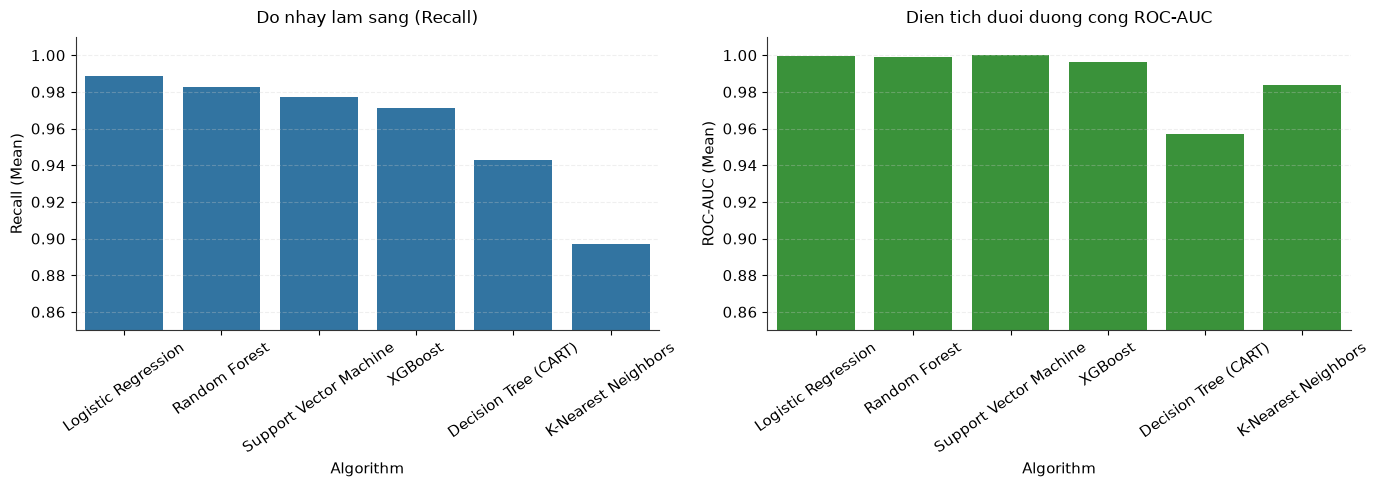

In [11]:
df_baseline = pd.DataFrame(experiment_log)
df_baseline = df_baseline.sort_values(by=['Recall (Mean)', 'ROC-AUC (Mean)', 'F1-Score (Mean)'], ascending=False).reset_index(drop=True)

print("=== BANG TONG HOP DOI SANH 6 MO HINH BASELINE (5-FOLD CV) ===")
print(df_baseline.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bieu do 1: Recall
sns.barplot(data=df_baseline, x='Algorithm', y='Recall (Mean)', color='#1f77b4', ax=axes[0])
axes[0].set_title('Do nhay lam sang (Recall)', fontsize=12, pad=10)
axes[0].set_ylabel('Recall (Mean)')
axes[0].set_ylim(0.85, 1.01)
axes[0].tick_params(axis='x', rotation=35)
sns.despine(ax=axes[0], top=True, right=True)

# Bieu do 2: ROC-AUC
sns.barplot(data=df_baseline, x='Algorithm', y='ROC-AUC (Mean)', color='#2ca02c', ax=axes[1])
axes[1].set_title('Dien tich duoi duong cong ROC-AUC', fontsize=12, pad=10)
axes[1].set_ylabel('ROC-AUC (Mean)')
axes[1].set_ylim(0.85, 1.01)
axes[1].tick_params(axis='x', rotation=35)
sns.despine(ax=axes[1], top=True, right=True)

plt.tight_layout()
plt.show()

### [Buoc 5.1] Tinh chinh sieu tham so cho Random Forest bang GridSearchCV
- Muc tieu ky thuat: Tim kiem luoi tham so cho Random Forest gom so cay con n_estimators, do sau toi da max_depth va so mau toi thieu phan tach min_samples_split voi ham muc tieu scoring='recall'.
- Co so khoa hoc:
  - Breiman, L. (2001) [5].
  - Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. JMLR, 13, pp. 281-305.

In [12]:
pipe_rf = Pipeline([
    ('preprocessor', ckd_preprocessing.make_preprocessor()),
    ('classifier', RandomForestClassifier(random_state=SEED))
])

param_grid_rf = {
    'classifier__n_estimators': [50, 100, 150],
    'classifier__max_depth': [None, 5, 8],
    'classifier__min_samples_split': [2, 4],
    'classifier__criterion': ['gini', 'entropy']
}

grid_rf = GridSearchCV(
    pipe_rf,
    param_grid=param_grid_rf,
    cv=cv_stratified,
    scoring='recall',
    n_jobs=1
)

grid_rf.fit(X_train_raw, y_train)
best_rf_model = grid_rf.best_estimator_

tuned_results = {
    'Random Forest': {
        'best_params': grid_rf.best_params_,
        'best_cv_recall': grid_rf.best_score_,
        'model': best_rf_model
    }
}

print(f"Random Forest Best CV Recall: {grid_rf.best_score_:.4f}")
print("Sieu tham so toi uu:", grid_rf.best_params_)

Random Forest Best CV Recall: 0.9886
Sieu tham so toi uu: {'classifier__criterion': 'gini', 'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 50}


### [Buoc 5.2] Tinh chinh sieu tham so cho XGBoost bang GridSearchCV
- Muc tieu ky thuat: Toi uu hoa toc do hoc learning_rate, do sau cay max_depth va ty le lay mau subsample cua XGBoost voi ham muc tieu scoring='recall'.
- Co so khoa hoc:
  - Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System [3].

In [13]:
pipe_xgb = Pipeline([
    ('preprocessor', ckd_preprocessing.make_preprocessor()),
    ('classifier', XGBClassifier(eval_metric='logloss', random_state=SEED, n_jobs=1))
])

param_grid_xgb = {
    'classifier__n_estimators': [100, 50, 150],
    'classifier__learning_rate': [0.05, 0.1, 0.01],
    'classifier__max_depth': [3, 2, 4],
    'classifier__subsample': [1.0, 0.8]
}

grid_xgb = GridSearchCV(
    pipe_xgb,
    param_grid=param_grid_xgb,
    cv=cv_stratified,
    scoring='recall',
    n_jobs=1
)

grid_xgb.fit(X_train_raw, y_train)
best_xgb_model = grid_xgb.best_estimator_

tuned_results['XGBoost'] = {
    'best_params': grid_xgb.best_params_,
    'best_cv_recall': grid_xgb.best_score_,
    'model': best_xgb_model
}

print(f"XGBoost Best CV Recall: {grid_xgb.best_score_:.4f}")
print("Sieu tham so toi uu:", grid_xgb.best_params_)

XGBoost Best CV Recall: 0.9771
Sieu tham so toi uu: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 100, 'classifier__subsample': 1.0}


### [Buoc 5.3] Tinh chinh sieu tham so cho Support Vector Machine bang GridSearchCV
- Muc tieu ky thuat: Duyet luoi tham so he so dieu chuan C, he so gamma va ham nhan kernel (rbf, linear) voi ham muc tieu scoring='recall'.
- Co so khoa hoc:
  - Cortes, C., & Vapnik, V. (1995) [2].
  - Hsu, C. W. et al. (2003). A practical guide to support vector classification.

In [14]:
pipe_svm = Pipeline([
    ('preprocessor', ckd_preprocessing.make_preprocessor()),
    ('classifier', SVC(probability=True, random_state=SEED))
])

param_grid_svm = {
    'classifier__C': [1.0, 10.0],
    'classifier__gamma': ['scale', 'auto', 0.01, 0.1],
    'classifier__kernel': ['linear', 'rbf']
}

grid_svm = GridSearchCV(
    pipe_svm,
    param_grid=param_grid_svm,
    cv=cv_stratified,
    scoring='recall',
    n_jobs=1
)

grid_svm.fit(X_train_raw, y_train)
best_svm_model = grid_svm.best_estimator_

tuned_results['SVM'] = {
    'best_params': grid_svm.best_params_,
    'best_cv_recall': grid_svm.best_score_,
    'model': best_svm_model
}

print(f"SVM Best CV Recall: {grid_svm.best_score_:.4f}")
print("Sieu tham so toi uu:", grid_svm.best_params_)

SVM Best CV Recall: 0.9886
Sieu tham so toi uu: {'classifier__C': 1.0, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}


### [Buoc 5.4] Doi sanh cac mo hinh sau tinh chinh tren tap kiem thu doc lap (Test Set)
- Muc tieu ky thuat: Kiem dinh 3 mo hinh da tinh chinh tren tap Test doc lap (X_test_raw.csv, y_test.csv gom 120 benh nhan chua tung tham gia huan luyen), tinh toan Test Accuracy, Test Recall, Test Precision, Test F1 va Test ROC-AUC.
- Co so khoa hoc:
  - Feurer, M., & Hutter, F. (2019). Hyperparameter optimization. Automated Machine Learning, Springer, pp. 3-33.

In [15]:
comparison_data = []

for model_name, res in tuned_results.items():
    model = res['model']
    y_pred = model.predict(X_test_raw)
    y_prob = model.predict_proba(X_test_raw)[:, 1] if hasattr(model, 'predict_proba') else None
    
    test_acc = accuracy_score(y_test, y_pred)
    test_rec = recall_score(y_test, y_pred)
    test_prec = precision_score(y_test, y_pred)
    test_f1 = f1_score(y_test, y_pred)
    test_auc = roc_auc_score(y_test, y_prob) if y_prob is not None else 0.0
    
    comparison_data.append({
        'Model': model_name,
        'Best CV Recall': res['best_cv_recall'],
        'Test Accuracy': test_acc,
        'Test Recall': test_rec,
        'Test Precision': test_prec,
        'Test F1-Score': test_f1,
        'Test ROC-AUC': test_auc
    })

df_tuned = pd.DataFrame(comparison_data).sort_values(by=['Test Recall', 'Test F1-Score', 'Test ROC-AUC'], ascending=False)
print("=== BANG KET QUA DOI SANH MO HINH SAU TINH CHINH TREN TAP TEST ===")
print(df_tuned.to_string(index=False))

=== BANG KET QUA DOI SANH MO HINH SAU TINH CHINH TREN TAP TEST ===
        Model  Best CV Recall  Test Accuracy  Test Recall  Test Precision  Test F1-Score  Test ROC-AUC
      XGBoost        0.977143       0.991667     0.986667        1.000000       0.993289      0.999704
Random Forest        0.988571       0.983333     0.986667        0.986667       0.986667      0.999704
          SVM        0.988571       0.983333     0.973333        1.000000       0.986486      0.999407


### [Buoc 6.1] Dong goi va luu tru mo hinh hop nhat (models/best_model.joblib)
- Muc tieu ky thuat: Lua chon mo hinh co Recall cao nhat va on dinh nhat. Huan luyen lai pipeline hop nhat tren toan bo 280 mau Train tho va luu tru ra file models/best_model.joblib theo dung quy dinh ban giao Zero Training-Serving Skew.
- Co so khoa hoc:
  - Sculley, D. et al. (2015). Hidden technical debt in machine learning systems. NeurIPS, pp. 2503-2511.
  - Huong dan ban giao Chuong 2 & Chuong 3 (Bao cao Do an Nhom 01, 2026).

In [16]:
best_model_name = df_tuned.iloc[0]['Model']
best_pipeline = tuned_results[best_model_name]['model']

print(f"Mo hinh duoc lua chon de dong goi ban giao: {best_model_name}")

# Huan luyen lai pipeline tren toan bo tap Train
best_pipeline.fit(X_train_raw, y_train)

# Thu muc luu tru models
model_dir = os.path.join('..', 'models')
if not os.path.exists(model_dir):
    model_dir = 'models'
os.makedirs(model_dir, exist_ok=True)

model_path = os.path.join(model_dir, 'best_model.joblib')
joblib.dump(best_pipeline, model_path)

file_size_kb = os.path.getsize(model_path) / 1024
print(f"Luu tru thanh cong mo hinh tai: {os.path.abspath(model_path)}")
print(f"Dung luong tep: {file_size_kb:.2f} KB")

Mo hinh duoc lua chon de dong goi ban giao: XGBoost


Luu tru thanh cong mo hinh tai: D:\2 Personal Activities\Study Folder\University\Năm Ba\Học máy\Đồ Án Học Máy\Training-A.I-model-for-diagnosing-kidney-disease-main\models\best_model.joblib
Dung luong tep: 106.83 KB


### [Buoc 6.2] Bao cao Ma tran nham lan va Bang chi so tong the tren tap Test
- Muc tieu ky thuat: Danh gia toan dien mo hinh dong goi tren tap Test doc lap 120 mau thong qua Ma tran nham lan va Bao cao phan lop, kiem tra cu the so ca bo sot (False Negative).
- Co so khoa hoc:
  - Provost, F., Fawcett, T., & Kohavi, R. (1998). The case against accuracy estimation for comparing induction algorithms. ICML, pp. 445-453.

In [17]:
final_loaded_model = joblib.load(model_path)
y_test_pred = final_loaded_model.predict(X_test_raw)
y_test_prob = final_loaded_model.predict_proba(X_test_raw)[:, 1]

cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()

print("=== MA TRAN NHAM LAN TREN TAP TEST DOC LAP (120 MAU) ===")
print(f"True Negative (Lanh benh dung): {tn}")
print(f"False Positive (Bao dong nham): {fp}")
print(f"False Negative (Bo sot ca benh): {fn}")
print(f"True Positive (Phat hien dung): {tp}")

print("\n=== CHI TIET BAO CAO PHAN LOP ===")
print(classification_report(y_test, y_test_pred, target_names=['Not CKD (0)', 'CKD (1)'], digits=4))

=== MA TRAN NHAM LAN TREN TAP TEST DOC LAP (120 MAU) ===


True Negative (Lanh benh dung): 45
False Positive (Bao dong nham): 0
False Negative (Bo sot ca benh): 1
True Positive (Phat hien dung): 74

=== CHI TIET BAO CAO PHAN LOP ===
              precision    recall  f1-score   support

 Not CKD (0)     0.9783    1.0000    0.9890        45
     CKD (1)     1.0000    0.9867    0.9933        75

    accuracy                         0.9917       120
   macro avg     0.9891    0.9933    0.9911       120
weighted avg     0.9918    0.9917    0.9917       120



### [Buoc 6.3] Kiem thu khoi (Smoke Test) va kiem dinh suy luan doc lap
- Muc tieu ky thuat: Nap truc tiep models/best_model.joblib, truyen vao mot ban ghi benh nhan gom 24 thuoc tinh tho (theo format DataFrame dung chuoi ten cot) va xac thuc ket qua tra ve nhan du doan kem xac suat phan tram.
- Co so khoa hoc:
  - Google Inc. (2020). Rules of Machine Learning: Best Practices for ML Engineering.
  - Quy chuan Feature Ordering Contract va Giao tiep Web Client - Server (Chuong 5).

In [18]:
sample_patient = pd.DataFrame([{
    'age': 55.0,
    'bp': 80.0,
    'sg': '1.015',
    'al': '2',
    'su': '0',
    'rbc': 'normal',
    'pc': 'abnormal',
    'pcc': 'present',
    'ba': 'notpresent',
    'bgr': 140.0,
    'bu': 58.0,
    'sc': 3.4,
    'sod': 135.0,
    'pot': 4.9,
    'hemo': 9.8,
    'pcv': 32.0,
    'wc': 7800.0,
    'rc': 3.9,
    'htn': 'yes',
    'dm': 'yes',
    'cad': 'no',
    'appet': 'poor',
    'pe': 'yes',
    'ane': 'yes'
}])

pred_class = final_loaded_model.predict(sample_patient)[0]
pred_probs = final_loaded_model.predict_proba(sample_patient)[0]

label_text = "CKD (Mac benh than man tinh)" if pred_class == 1 else "Not CKD (Khong mac benh)"
print("=== KET QUA KIEM THU KHOI (SMOKE TEST) ===")
print(f"Nhan du doan: {pred_class} - {label_text}")
print(f"Xac suat CKD: {pred_probs[1] * 100:.2f}%")
print(f"Xac suat Not CKD: {pred_probs[0] * 100:.2f}%")
print("Kiem thu thanh cong: Mo hinh hoat dong on dinh tren du lieu tho 24 dac trung.")

=== KET QUA KIEM THU KHOI (SMOKE TEST) ===
Nhan du doan: 1 - CKD (Mac benh than man tinh)
Xac suat CKD: 99.38%
Xac suat Not CKD: 0.62%
Kiem thu thanh cong: Mo hinh hoat dong on dinh tren du lieu tho 24 dac trung.
